# CW 2 - AIR_A

## Import all necessary libraries

In [ ]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import time

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.metrics import make_scorer

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor as KNN
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

## Load data and initialise baseline pipeline

In [ ]:
# Load the data
MY_FILE = "air-quality.csv"

raw = pd.read_csv(MY_FILE)

# Target and dropped columns
TARGET = "co_gt"
DROP = ["datetime", "nmhc_gt", "c6h6_gt", "nox_gt", "no2_gt", "absolute_humidity"]

df = raw.drop(columns=DROP)
df = df.replace(-200, np.nan)        # -200 means missing
df = df.dropna(subset=[TARGET])      # rows without a target can't be used
    
y = df[TARGET]
X = df.drop(columns=[TARGET])

numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols),


# This can be removed: we do not have categorical variables
    # ("cat", Pipeline([
    #     ("impute", SimpleImputer(strategy="most_frequent")),
    #     ("onehot", OneHotEncoder(handle_unknown="ignore")) 
    # ]), text_cols)
])

pipe = Pipeline([
    ("prep", preprocess),
    ("model", LinearRegression())
])

## Initialise Cross-Validation

In [3]:
# CROSS-VALIDATION
 
N_FOLDS = 5
METRIC = "neg_mean_absolute_error"

NO2 = raw["no2_gt"].replace(-200, np.nan)

#sensitivity
# draws a straight line through (real CO, predicted CO) and returns its slope.
# 1 = perfect
def sensitivity(y_true, y_pred):
    slope = np.polyfit(y_true, y_pred, 1)[0]
    return slope
# selectivity : how much do the predictions follow CO, compared with NO2
# higher the better, number wise
def selectivity(model, X, y):
    y_pred = model.predict(X)

    # get the real NO2 for these same rows
    no2 = NO2.loc[X.index].to_numpy()

    # ignore rows where NO2 is missing
    keep = ~np.isnan(no2)
    real_co = np.asarray(y)[keep]
    no2 = no2[keep]
    y_pred = y_pred[keep]

    # put CO, NO2 and predictions on the same scale (CO and NO2 use different units)
    def rescale(v):
        return (v - v.mean()) / v.std()

    inputs = np.column_stack([rescale(real_co), rescale(no2)])

    # how strongly do predictions follow CO, and how strongly do they follow NO2?
    follow_co, follow_no2 = LinearRegression().fit(inputs, rescale(y_pred)).coef_

    return abs(follow_co / follow_no2)
 
SCORING = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "SENS": make_scorer(sensitivity), 
    "SEL": selectivity,
}
 
# 1. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
 
# 2. Cross-validation folds
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=0)
 
# 3. Cross-validation helper
def run_cv(name, model):
    s = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=SCORING,
        return_train_score=True
    )
 
    return {
        "model": name,
        "Train MAE": -s["train_MAE"].mean(),
        "CV MAE": -s["test_MAE"].mean(),
        "CV RMSE": -s["test_RMSE"].mean(),
        "CV R²": s["test_R2"].mean(),
        "spread": s["test_MAE"].std(),
        "fit time (s)": s["fit_time"].mean()
    }
 
# 4. GridSearchCV results helper
def show_results(title, search):
    best = search.best_index_
    r = search.cv_results_
 
    print(title)
    print("  Best settings:", search.best_params_)
    print("  Training MAE:", round(-r["mean_train_score"][best], 3))
    print("  Cross-validation MAE:", round(-search.best_score_, 3))
    print("  Spread across folds:", round(r["std_test_score"][best], 3))
    print("  Training time (s):", round(r["mean_fit_time"][best], 3))
    print("  Prediction time (s):", round(r["mean_score_time"][best], 4))
    print()
 
# 5. Linear regression baseline
print(f"train {len(X_train)} rows, test {len(X_test)} rows, {N_FOLDS} folds\n")
 
print(pd.DataFrame([
    run_cv("linear regression", pipe)
]).round(3).to_string(index=False))

train 6139 rows, test 1535 rows, 5 folds

            model  Train MAE  CV MAE  CV RMSE  CV R²  spread  fit time (s)
linear regression      0.369    0.37    0.612  0.825    0.01         0.065


## kNN

In [ ]:
knn_model = KNN(n_neighbors=50)

# 3. Build the final pipeline
pipe = Pipeline([
    ("prep", preprocess),
    ("model", knn_model)
])

# Fit the pipeline directly on the raw, unscaled training features to prevent leakage
pipe.fit(X_train_filtered, y_train)

# Predict using the pipeline directly on the raw, unscaled test features
y_test_predictions = pipe.predict(X_test_filtered)

# Plot the results to verify
plt.figure(figsize=(4.5, 3), dpi=200)
plt.plot(y_test, y_test_predictions, 'g.', markersize=4)
lim_left, lim_right = plt.xlim()
plt.plot([lim_left, lim_right], [lim_left, lim_right], '--k', linewidth=1)
plt.xlabel("y (Actual co_gt)", fontsize='small')
plt.ylabel(r"$\hat{y}$ (Predicted co_gt)", fontsize='small')
plt.tick_params(axis='both', labelsize=7)
plt.show()

## SVR

## Gradient Boosting

## Random forest regression

### Decision Tree Regressor

Benjamin's code

decision tree tests different feature values to split data into groups and make predictions based on learned patterns

Most precise depth was tested to be 12 with the ideal sample leafs taken as 24 Was tested through taking a range of values, however repeating this takes ages to load the code

In [ ]:
from sklearn.ensemble import RandomForestRegressor


# Random Forest pipeline

rf_pipe = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestRegressor(random_state=0))
])


# STEP 1: Wide search to identify the best hyperparameter region

wide_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [5, 10, 20],
    "model__max_features": [0.5, 1.0]
}

wide_search_rf = GridSearchCV(
    rf_pipe,
    wide_grid,
    cv=cv,
    scoring=METRIC,
    return_train_score=True,
    n_jobs=-1
)

wide_search_rf.fit(X_train, y_train)

show_results("WIDE SEARCH", wide_search_rf)


# STEP 2: Narrow search around the best hyperparameter region

narrow_grid = {
    "model__n_estimators": [150, 200, 250],
    "model__max_depth": [15, 20, 25, None],
    "model__min_samples_leaf": [5, 7, 10, 15],
    "model__max_features": [0.4, 0.5, 0.6]
}

search_rf = GridSearchCV(
    rf_pipe,
    narrow_grid,
    cv=cv,
    scoring=METRIC,
    return_train_score=True,
    n_jobs=-1
)

search_rf.fit(X_train, y_train)

show_results("NARROW SEARCH (final)", search_rf)

WIDE SEARCH
  Best settings: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
  Training MAE: 0.239
  Cross-validation MAE: 0.317
  Spread across the folds: 0.013
  Training time (s): 1.465
  Prediction time for one fold (s): 0.0278

NARROW SEARCH (final)
  Best settings: {'model__max_depth': 25, 'model__max_features': 0.6, 'model__min_samples_leaf': 5, 'model__n_estimators': 250}
  Training MAE: 0.234
  Cross-validation MAE: 0.316
  Spread across the folds: 0.012
  Training time (s): 2.495
  Prediction time for one fold (s): 0.0387



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Best trained models
linear_model = pipe.fit(X_train, y_train)
tree_model = search.best_estimator_
forest_model = search_rf.best_estimator_

# Predictions on the same test set
linear_pred = linear_model.predict(X_test)
tree_pred = tree_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

models = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred
}

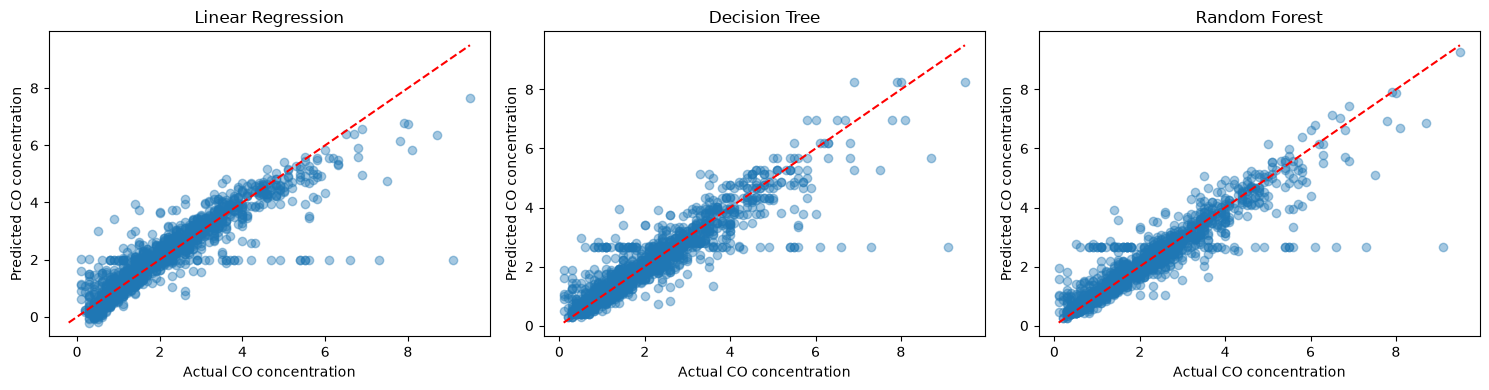

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    ax.scatter(y_test, predictions, alpha=0.4)

    # Perfect prediction line
    minimum = min(y_test.min(), predictions.min())
    maximum = max(y_test.max(), predictions.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual CO concentration")
    ax.set_ylabel("Predicted CO concentration")

plt.tight_layout()
plt.show()

In [ ]:
names = []
mae_scores = []
rmse_scores = []
r2_scores = []

for name, predictions in models.items():

    names.append(name)

    mae_scores.append(
        mean_absolute_error(y_test, predictions)
    )

    rmse_scores.append(
        np.sqrt(mean_squared_error(y_test, predictions))
    )

    r2_scores.append(
        r2_score(y_test, predictions)
    )


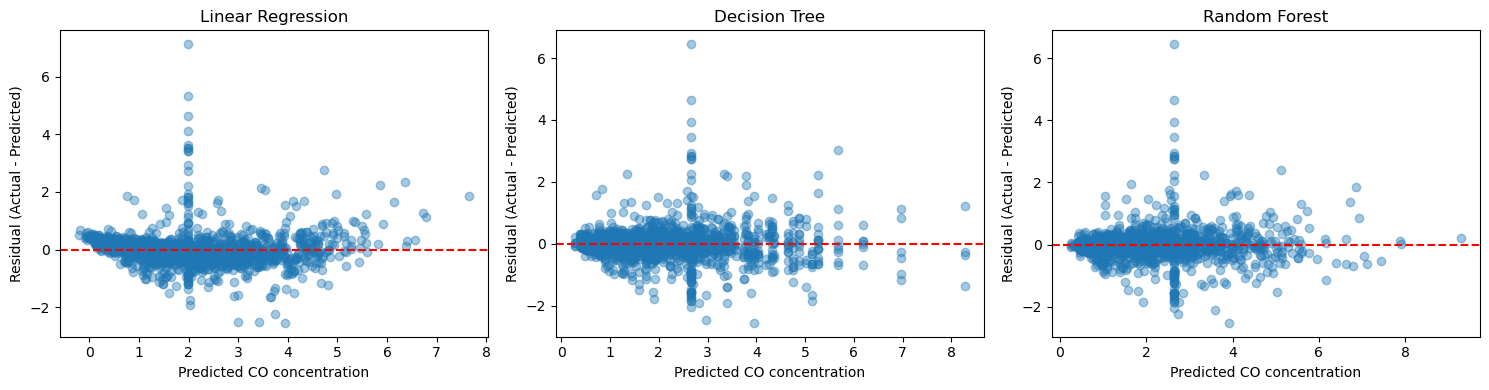

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    residuals = y_test - predictions

    ax.scatter(predictions, residuals, alpha=0.4)

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Predicted CO concentration")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

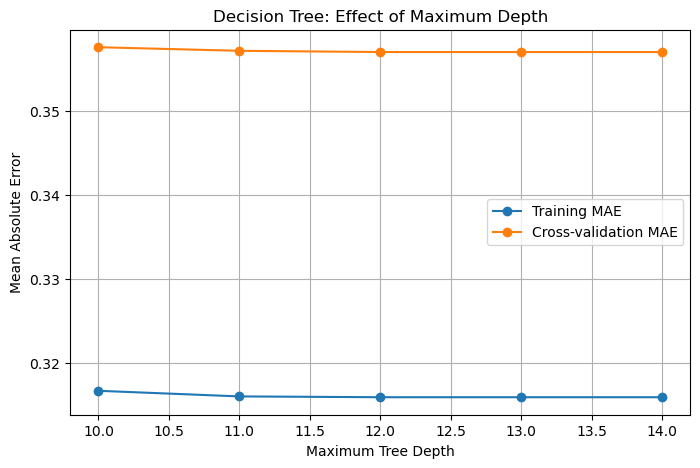

In [ ]:
# Get results from the Decision Tree grid search
results = pd.DataFrame(search.cv_results_)

# Keep the best min_samples_leaf setting fixed
best_leaf = search.best_params_["model__min_samples_leaf"]

filtered = results[
    results["param_model__min_samples_leaf"] == best_leaf
].sort_values("param_model__max_depth")

depth = filtered["param_model__max_depth"]

train_mae = -filtered["mean_train_score"]
cv_mae = -filtered["mean_test_score"]

plt.figure(figsize=(8, 5))

plt.plot(depth, train_mae, "o-", label="Training MAE")
plt.plot(depth, cv_mae, "o-", label="Cross-validation MAE")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean Absolute Error")
plt.title("Decision Tree: Effect of Maximum Depth")

plt.legend()
plt.grid(True)
plt.show()

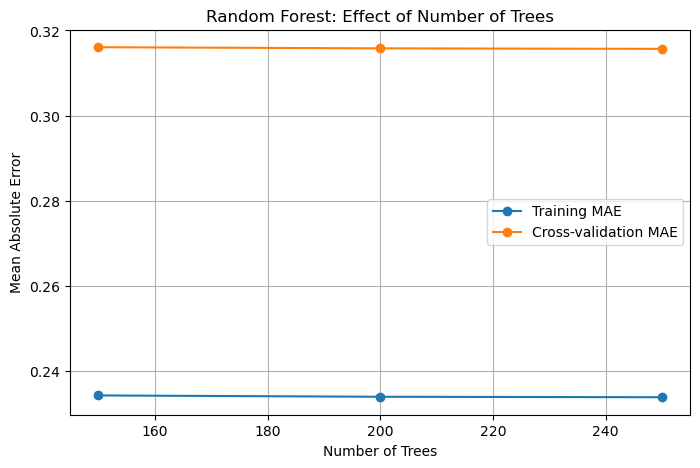

In [ ]:
# Get Random Forest grid search results
results_rf = pd.DataFrame(search_rf.cv_results_)

# Keep other hyperparameters fixed
best_depth = search_rf.best_params_["model__max_depth"]
best_leaf = search_rf.best_params_["model__min_samples_leaf"]
best_features = search_rf.best_params_["model__max_features"]

filtered_rf = results_rf[
    (results_rf["param_model__max_depth"] == best_depth) &
    (results_rf["param_model__min_samples_leaf"] == best_leaf) &
    (results_rf["param_model__max_features"] == best_features)
].sort_values("param_model__n_estimators")

n_trees = filtered_rf["param_model__n_estimators"]

train_mae_rf = -filtered_rf["mean_train_score"]
cv_mae_rf = -filtered_rf["mean_test_score"]

plt.figure(figsize=(8, 5))

plt.plot(n_trees, train_mae_rf, "o-", label="Training MAE")
plt.plot(n_trees, cv_mae_rf, "o-", label="Cross-validation MAE")

plt.xlabel("Number of Trees")
plt.ylabel("Mean Absolute Error")
plt.title("Random Forest: Effect of Number of Trees")

plt.legend()
plt.grid(True)
plt.show()

### Random Forest Feature Importance

Bar chart showing the relative importance of the input features used by the Random Forest model to predict CO concentration. Longer bars indicates greater feature importance.

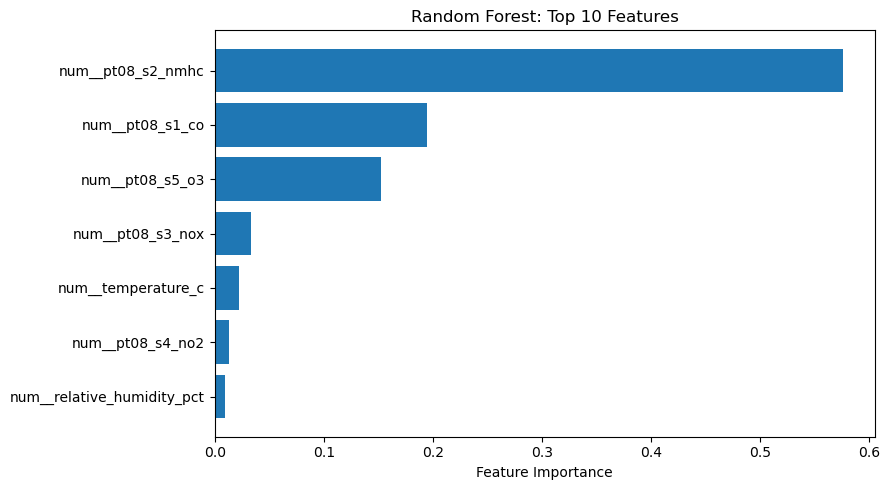

In [ ]:
# Get feature names after preprocessing
feature_names = forest_model.named_steps["prep"].get_feature_names_out()

# Get Random Forest feature importances
importances = forest_model.named_steps["model"].feature_importances_

# Create and sort the results
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

# Plot the 10 most important features
top_features = importance_df.head(10)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest: Top 10 Features")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Cost analysis

In [ ]:
# Load the data, parse dates, and sort in true chronological order.
df = pd.read_csv(r"C:\Users\44747\Desktop\3. AI\Data\air-quality.csv")
df["datetime"] = pd.to_datetime(df["datetime"], format="%Y-%m-%d %H:%M:%S")
df = df.sort_values("datetime").replace(-200, float("nan"))

# Keep rows with a known CO value for this model comparison.
known_co = df.dropna(subset=["co_gt"])

# Use the other measurements to predict CO.
X = known_co.drop(columns=["datetime", "co_gt"])
y = known_co["co_gt"]

# Train on the earlier 80% and test on the later 20%.
split = int(len(known_co) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Each pipeline imputes missing inputs; kNN also scales features.
models = {
    "Decision tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeRegressor(random_state=0),
    ),
    "Random forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=25, max_depth=8, random_state=0, n_jobs=1
        ),
    ),
    "kNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5),
    ),
    "Gradient boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingRegressor(random_state=0),
    ),
}

results = []

for name, model in models.items():
    fit_times_ms = []

    # Repeat fitting to reduce the effect of one unusually fast or slow run.
    for _ in range(3):
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_times_ms.append((time.perf_counter() - start) * 1000)

    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    median_fit_ms = sorted(fit_times_ms)[1]

    results.append({
        "Model": name,
        "Test MAE": mae,
        "Median fit time (ms)": median_fit_ms,
        "Meets MAE <= 0.3": mae <= 0.3,
        "Meets fit time < 100 ms": median_fit_ms < 100,
        "Meets both": mae <= 0.3 and median_fit_ms < 100,
    })

results_df = pd.DataFrame(results).sort_values("Test MAE")
print(results_df.to_string(index=False, formatters={
    "Test MAE": "{:.3f}".format,
    "Median fit time (ms)": "{:.1f}".format,
}))

if results_df["Meets both"].any():
    print("\nAt least one model met both targets on this test split.")
else:
    print("\nNo model met both targets on this test split.")

            Model Test MAE Median fit time (ms)  Meets MAE <= 0.3  Meets fit time < 100 ms  Meets both
Gradient boosting    0.348               1753.3             False                    False       False
    Random forest    0.368                806.0             False                    False       False
              kNN    0.451                 14.4             False                     True       False
    Decision tree    0.587                 73.7             False                     True       False

No model met both targets on this test split.
